In [1]:
import numpy as np
import xarray as xr
from scipy.signal import savgol_filter
from scipy.interpolate import interp1d

import glob
import os
import warnings
from collections import defaultdict
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import matplotlib.patches as mpatches
import matplotlib.patheffects as pe
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import matplotlib.ticker as mticker
import cmocean
import matplotlib.gridspec as gridspec
from matplotlib.lines import Line2D


from swot_analysis import compute_pass_spectra
from swot_analysis import load_swot_l2_expert 


In [89]:
DATA_DIR = '/Volumes/PortableSSD/diags_2024/'
GDP_FILE = "/Volumes/PortableSSD/gdp_energy.nc"
LLC_FILE = "/Volumes/PortableSSD/llc_energy.nc"
BOX_DEG  = 2.0 

In [112]:
#--------- SWOT spectra -------------------
ds_expert = xr.open_dataset(DATA_DIR +'swot_segments2D_1000km_demean.nc')
ds_expert_hret = xr.open_dataset(DATA_DIR +'swot_segments2D_1000km_demean_notide.nc')
ds250_expert = xr.open_dataset(DATA_DIR +'swot_segments2D_250km_demean.nc')

#--------- GDP KE -------------------
ds_gdp = xr.open_dataset(GDP_FILE)

#--------- LLC4320 KE -------------------
ds_llc = xr.open_dataset(LLC_FILE)
ds_llc = ds_llc.groupby_bins('lon_bin',bins=np.arange(-181,179,2)).mean().groupby_bins('lat_bin',bins=np.arange(-60,61,2)).mean()
ds_llc = ds_llc.assign_coords({'lat_bin_bins':ds_gdp.lat.values}).rename({'lat_bin_bins':'lat'})
ds_llc = ds_llc.assign_coords({'lon_bin_bins':ds_gdp.lon.values}).rename({'lon_bin_bins':'lon'})

In [113]:
def build_box_dataset(ds_segments: xr.Dataset,
                      box_deg: float = 2.0,
                      method: str = 'mean',
                      min_sampling_fraction: float = 0.5) -> xr.Dataset:
    from collections import defaultdict
    lat     = ds_segments['lat_mean'].values
    lon     = ds_segments['lon_mean'].values
    lat_idx = np.floor(lat / box_deg).astype(int)
    lon_idx = np.floor(lon / box_deg).astype(int)
    box_to_segs = defaultdict(list)
    for i, key in enumerate(zip(lat_idx, lon_idx)):
        box_to_segs[key].append(i)
    psd_all    = ds_segments['psd'].values
    wavenumber = ds_segments['wavenumber'].values
    rows_lat, rows_lon, rows_n, rows_psd = [], [], [], []
    for (li, loi), idxs in sorted(box_to_segs.items()):
        if method=='mean':
            rows_psd.append(np.nanmean(psd_all[idxs, :], axis=0))
        elif method=='median':
            rows_psd.append(np.nanmedian(psd_all[idxs, :], axis=0))
        elif method == "log":
            log_spectra = np.log(psd_all[idxs, :])          # natural log; log10 works identically up to a constant
            rows_psd.append(np.exp(np.nanmean(log_spectra, axis=0)))
         
        else:
            print("Method is not defined!")
        rows_n.append(len(idxs))
        rows_lat.append((li  + 0.5) * box_deg)
        rows_lon.append((loi + 0.5) * box_deg)
    n_segments = np.array(rows_n)
    n_max      = n_segments.max()
    keep       = n_segments >= min_sampling_fraction * n_max
    psd_stack  = np.stack(rows_psd, axis=0)
    lat_mean   = np.array(rows_lat)
    lon_mean   = np.array(rows_lon)
    return xr.Dataset(
        data_vars=dict(
            mean_psd=(['box', 'wavenumber'], psd_stack[keep],
                      {'long_name': 'Box-mean SSH(A) PSD', 'units': 'm^2 / (cycles/km)'}),
            n_segments=(['box'], n_segments[keep]),
            sampling_fraction=(['box'], n_segments[keep] / n_max),
        ),
        coords=dict(wavenumber=('wavenumber', wavenumber, {'units': 'cycles/km'}),
            box=('box', np.arange(keep.sum())),
            lat_mean=('box', lat_mean[keep], {'units': 'degrees_north'}),
            lon_mean=('box', lon_mean[keep], {'units': 'degrees_east'}),
        ),
        attrs=dict(box_size_deg=box_deg,
                   min_sampling_fraction=min_sampling_fraction),
    )


def plot_box(var: np.array, lon: np.array, lat: np.array,
             box_deg: float = None,
             projection: ccrs = ccrs.Robinson(), cmap: str = "viridis",
             figsize: tuple = (14, 7),
             title: str = "Number of observations per box", label: str = "Number of observations",
             norm: norm = None, vmin: float = None, vmax: float = None,
             fig: fig = None, ax: ax = None
            ):
    mask = np.isfinite(var)
    lon = lon[mask]
    lat = lat[mask]
    var = var[mask]

    # Infer box size from the spacing of box centers if not given
    if box_deg is None:
        lat_diffs = np.diff(np.unique(np.round(lat, 6)))
        lon_diffs = np.diff(np.unique(np.round(lon, 6)))
        box_deg = np.min(np.concatenate([lat_diffs, lon_diffs]))

    # Reconstruct the regular grid of box centers
    lat_centers = np.arange(lat.min(), lat.max() + box_deg, box_deg)
    lon_centers = np.arange(lon.min(), lon.max() + box_deg, box_deg)

    lat_idx = np.round((lat - lat_centers[0]) / box_deg).astype(int)
    lon_idx = np.round((lon - lon_centers[0]) / box_deg).astype(int)

    grid = np.full((lat_centers.size, lon_centers.size), np.nan)
    grid[lat_idx, lon_idx] = var

    # pcolormesh wants cell edges, not centers
    lat_edges = np.concatenate([lat_centers - box_deg / 2, [lat_centers[-1] + box_deg / 2]])
    lon_edges = np.concatenate([lon_centers - box_deg / 2, [lon_centers[-1] + box_deg / 2]])

    if ax is None:
        fig = plt.figure(figsize=figsize)
        ax = plt.axes(projection=projection)
    ax.set_global()
    ax.add_feature(cfeature.LAND, facecolor="0.9", edgecolor="none")
    ax.add_feature(cfeature.COASTLINE, linewidth=0.6)
    ax.add_feature(cfeature.BORDERS, linewidth=0.3)
    gl = ax.gridlines(draw_labels=True, linewidth=0.3, linestyle="--", alpha=0.5)

    gl.top_labels = False
    gl.right_labels = False
    gl.xlocator = mticker.FixedLocator(np.arange(-180, 181, 60))
    gl.ylocator = mticker.FixedLocator(np.arange(-60, 61, 30))
    gl.xlabel_style = {"size": 10, "color": "black"}
    gl.ylabel_style = {"size": 10, "color": "black"}

    if norm is not None:
        sc = ax.pcolormesh(lon_edges, lat_edges, grid,
                            cmap=cmap, shading='flat',
                            transform=ccrs.PlateCarree(), norm=norm)
    else:
        if vmin is None:
            vmin, vmax = np.nanmin(var), np.nanmax(var)

        sc = ax.pcolormesh(lon_edges, lat_edges, grid,
                            cmap=cmap, shading='flat',
                            transform=ccrs.PlateCarree(), vmin=vmin, vmax=vmax)

    cb = plt.colorbar(sc, ax=ax, shrink=0.6,pad=0.05,orientation='vertical')
    cb.set_label(label)
    ax.set_title(title)

    return fig, ax
def estimate_separation_scale_adaptative(psd_all,
                                         wavenumber,
                                         log_k_uniform,
                                         dlogk,
                                         search_mask,
                                         low_k_band: tuple,
                                         high_k_band: tuple,
                                         smooth_window: int = 7,
                                         polyorder: int = 2,
                                         search_range: tuple = None,
                                         n_interp: int = 200,
                                         verbose: bool = False) -> xr.Dataset:
    
    p = psd_all
    valid = np.isfinite(p) & (p > 0)
    if valid.sum() < smooth_window:
        if verbose:
            print('Well well well')
        pass
    k = wavenumber[valid]
    logp = np.log10(p[valid])
    
    # --- Plateau slopes: simple linear fit on RAW (unsmoothed)
    # points within each band, so no window-straddling bias here ---
    low_mask = (k >= low_k_band[0]) & (k <= low_k_band[1])
    high_mask = (k >= high_k_band[0]) & (k <= high_k_band[1])

    if low_mask.sum() < 3 or high_mask.sum() < 3:
        if verbose:
            print(f"Box {i}: not enough points in plateau bands "
                  f"(low={low_mask.sum()}, high={high_mask.sum()}), skipping.")
        pass

    slope_low = np.polyfit(np.log10(k[low_mask]), logp[low_mask], 1)[0]
    slope_high = np.polyfit(np.log10(k[high_mask]), logp[high_mask], 1)[0]
    #slope_low_all[i] = slope_low
    #slope_high_all[i] = slope_high

    # Adaptive threshold: midpoint between the two plateau slopes
    threshold = 0.5 * (slope_low + slope_high)
    #threshold_used[i] = threshold

    # Expect mesoscale (low-k) STEEPER than sub-mesoscale (high-k),
    # i.e. slope_low < slope_high (more negative = steeper).
    if slope_low >= slope_high:
        if verbose:
            print(f"Box {i}: low-k slope ({slope_low:.2f}) not steeper "
                  f"than high-k slope ({slope_high:.2f}) — no clear "
                  f"mesoscale-to-submesoscale steepening-to-shallowing "
                  f"transition, skipping.")
        pass

    
    # --- Local slope curve via SG, same as before ---
    interp_fn = interp1d(np.log10(k), logp, bounds_error=False, fill_value=np.nan)
    logp_uniform = interp_fn(log_k_uniform)
    valid_u = ~np.isnan(logp_uniform)
    if valid_u.sum() < smooth_window:
        if verbose:
            print('Well well well')
        pass

    
    slope_curve = np.full(n_interp, np.nan)
    win = min(smooth_window, valid_u.sum() if valid_u.sum() % 2 == 1 else valid_u.sum() - 1)
    if win <= polyorder:
        if verbose:
            print('Well well well')
        pass
    slope_curve[valid_u] = savgol_filter(logp_uniform[valid_u], window_length=win,
                                              polyorder=polyorder, deriv=1, delta=dlogk)

    mask = search_mask & valid_u
    idxs = np.where(mask)[0]
    if len(idxs) < 2:
        if verbose:
            print(f"Box {i}: fewer than 2 points in search range, skipping.")
        pass

    diff = slope_curve[idxs] - threshold
    sign_change = np.where(np.diff(np.sign(diff)) != 0)[0]
    if len(sign_change) == 0:
        if verbose:
            print(f"Box {i}: slope never crosses adaptive threshold "
                  f"{threshold:.2f}.")
        pass
    try:
        j = sign_change[0]
        frac = -diff[j] / (diff[j + 1] - diff[j])
        i1, i2 = idxs[j], idxs[j + 1]
        log_k_cross = log_k_uniform[i1] + frac * (log_k_uniform[i2] - log_k_uniform[i1])
        separation_k = 10 ** log_k_cross
    except:
        separation_k = np.nan
    return separation_k, threshold,slope_low, slope_high
    
def wrap_separation_scale_adaptive(ds_box: xr.Dataset,
                                        low_k_band: tuple,
                                        high_k_band: tuple,
                                        smooth_window: int = 7,
                                        polyorder: int = 2,
                                        search_range: tuple = None,
                                        n_interp: int = 200,
                                        verbose: bool = False) -> xr.Dataset:
    """
    Non-parametric separation scale using an adaptive (per-box) slope
    threshold, calibrated to each spectrum's own mesoscale (low-k, steep)
    and sub-mesoscale (high-k, shallower) plateau slopes, instead of a
    fixed universal reference slope like -2.

    Physical convention: mesoscale (low-k) is expected to be steeper
    (more negative slope) than sub-mesoscale (high-k), consistent with
    the transition from geostrophic/QG turbulence (~ -5 to -11/3) to a
    shallower sub-mesoscale regime (~ -2 to -5/3).

    Parameters
    ----------
    low_k_band, high_k_band : tuple(float, float)
        Wavenumber ranges (cycles/km) used to estimate the plateau slope
        on each side of the transition, well away from the break itself.
    smooth_window, polyorder : SG smoothing parameters for the local-slope
        curve used to locate the crossing.
    search_range : tuple(float, float), optional
        Restrict the crossing search to this wavenumber range (defaults
        to the union of low_k_band and high_k_band).
    """
    wavenumber = ds_box['wavenumber'].values
    psd_all    = ds_box['mean_psd'].values
    n_boxes    = psd_all.shape[0]

    k_valid = wavenumber > 0
    wavenumber = wavenumber[k_valid]
    psd_all = psd_all[:, k_valid]
    log_k_orig = np.log10(wavenumber)

    if smooth_window % 2 == 0:
        smooth_window += 1

    log_k_uniform = np.linspace(log_k_orig.min(), log_k_orig.max(), n_interp)
    dlogk = log_k_uniform[1] - log_k_uniform[0]

    if search_range is None:
        k_lo = low_k_band[0]
        k_hi = high_k_band[1]
    else:
        k_lo, k_hi = search_range
    search_mask = (10**log_k_uniform >= k_lo) & (10**log_k_uniform <= k_hi)

    separation_k    = np.full(n_boxes, np.nan)
    slope_low_all   = np.full(n_boxes, np.nan)
    slope_high_all  = np.full(n_boxes, np.nan)
    threshold_used  = np.full(n_boxes, np.nan)

    for i in range(n_boxes):
        sep_k, threshold,slope_low, slope_high = estimate_separation_scale_adaptative(psd_all[i],wavenumber,log_k_uniform,dlogk,
                                                                                      search_mask,
                                                                                      low_k_band, high_k_band,
                                                                                     smooth_window = smooth_window,
                                                                                     polyorder=polyorder,
                                                                                     search_range = search_range,
                                                                                     n_interp=n_interp,
                                                                                     verbose=verbose)
        separation_k[i] = sep_k
        threshold_used[i] = threshold
        slope_low_all[i] = slope_low
        slope_high_all[i] = slope_high

    ds_out = ds_box.copy()
    ds_out['separation_wavenumber'] = (
        ['box'], separation_k,
        {'long_name': 'Wavenumber of adaptive-threshold slope crossing '
                       '(mesoscale-to-submesoscale transition)',
         'units': 'cycles/km'}
    )
    ds_out['separation_wavelength'] = (
        ['box'], 1.0 / separation_k,
        {'long_name': 'Separation scale (1/wavenumber)', 'units': 'km'}
    )
    ds_out['slope_low_k'] = (['box'], slope_low_all,
                              {'long_name': 'Fitted mesoscale (low-k) plateau slope'})
    ds_out['slope_high_k'] = (['box'], slope_high_all,
                               {'long_name': 'Fitted sub-mesoscale (high-k) plateau slope'})
    ds_out['adaptive_threshold'] = (['box'], threshold_used,
                                     {'long_name': 'Midpoint slope threshold used per box'})
    return ds_out

def build_latlon_dataset(ds_segments: xr.Dataset,
                      box_deg: float = 2.0,
                      method: str = 'mean',
                      min_sampling_fraction: float = 0.5,
                      var: str = 'psd') -> xr.Dataset:
    """
    Average segment spectra in lat/lon boxes and return a gridded dataset with
    dims (lat, lon, wavenumber). lat/lon are the box centres, on a regular axis
    covering all boxes; boxes with no segments, or fewer than
    ``min_sampling_fraction * n_max`` segments, are NaN (n_segments is 0 there).
    """
    from collections import defaultdict

    if method not in ('mean', 'median', 'log'):
        raise ValueError(f"method must be 'mean', 'median' or 'log', got {method!r}")

    lat = ds_segments['lat_mean'].values
    lon = ds_segments['lon_mean'].values
    lat_idx = np.floor(lat / box_deg).astype(int)
    lon_idx = np.floor(lon / box_deg).astype(int)

    box_to_segs = defaultdict(list)
    for i, key in enumerate(zip(lat_idx, lon_idx)):
        box_to_segs[key].append(i)

    psd_all = ds_segments[var].values
    wavenumber = ds_segments['wavenumber'].values

    # regular axes spanning all occupied boxes
    li_axis = np.arange(lat_idx.min(), lat_idx.max() + 1)
    lo_axis = np.arange(lon_idx.min(), lon_idx.max() + 1)
    n_max = max(len(v) for v in box_to_segs.values())

    psd_grid = np.full((li_axis.size, lo_axis.size, wavenumber.size), np.nan)
    n_grid = np.zeros((li_axis.size, lo_axis.size), dtype=int)

    for (li, loi), idxs in box_to_segs.items():
        if len(idxs) < min_sampling_fraction * n_max:
            continue
        sub = psd_all[idxs, :]
        if method == 'mean':
            p = np.nanmean(sub, axis=0)
        elif method == 'median':
            p = np.nanmedian(sub, axis=0)
        else:  # 'log': geometric mean
            with np.errstate(divide='ignore', invalid='ignore'):
                p = np.exp(np.nanmean(np.log(sub), axis=0))
        a, b = li - li_axis[0], loi - lo_axis[0]
        psd_grid[a, b] = p
        n_grid[a, b] = len(idxs)

    return xr.Dataset(
        data_vars=dict(
            mean_psd=(['lat', 'lon', 'wavenumber'], psd_grid,
                      {'long_name': 'Box-mean SSH(A) PSD', 'units': 'm^2 / (cycles/km)'}),
            n_segments=(['lat', 'lon'], n_grid),
            sampling_fraction=(['lat', 'lon'], n_grid / n_max),
        ),
        coords=dict(
            lat=('lat', (li_axis + 0.5) * box_deg, {'units': 'degrees_north'}),
            lon=('lon', (lo_axis + 0.5) * box_deg, {'units': 'degrees_east'}),
            wavenumber=('wavenumber', wavenumber, {'units': 'cycles/km'}),
        ),
        attrs=dict(box_size_deg=box_deg,
                   min_sampling_fraction=min_sampling_fraction),
    )

In [114]:
ds_boxes    = build_box_dataset(ds_expert,box_deg=BOX_DEG,min_sampling_fraction=0.15)
ds250_boxes = build_box_dataset(ds250_expert,box_deg=BOX_DEG,min_sampling_fraction=0.15)

ds_boxes_latlon         = build_latlon_dataset(ds_expert,box_deg=BOX_DEG,min_sampling_fraction=0.15)
ds_boxes_hret_latlon    = build_latlon_dataset(ds_expert_hret,box_deg=BOX_DEG,min_sampling_fraction=0.15)
ds250_boxes_latlon      = build_latlon_dataset(ds250_expert,box_deg=BOX_DEG,min_sampling_fraction=0.15)

In [146]:
import numpy as np
import xarray as xr
from scipy.ndimage import binary_dilation


import numpy as np, warnings

def make_k_edges(k, n_bands=20, min_bins=2):
    """
    Log-spaced band edges built from the actual wavenumber grid ``k`` (k > 0):
    every band holds at least ``min_bins`` bins, the lowest bin and the last
    (Nyquist) bin are included, and edges lie halfway between grid points.
    """
    k = np.asarray(k, float); k = k[k > 0]
    mid = np.sqrt(k[:-1] * k[1:])
    edges = np.r_[k[0] * (k[0] / mid[0]), mid, k[-1] * (k[-1] / mid[-1])]
    wanted = np.geomspace(edges[0], edges[-1], n_bands + 1)
    idx = np.unique(np.searchsorted(edges, wanted))          # snap to bin boundaries
    out = [idx[0]]
    for i in idx[1:]:
        if i - out[-1] >= min_bins:
            out.append(i)
    if out[-1] != idx[-1]:                                    # last band absorbs the remainder
        out[-1] = idx[-1]
    return edges[out]


def band_average_k(psd, k_edges, verbose=True):
    """
    psd: (lat, lon, wavenumber) -> (lat, lon, kc). Bands are [lo, hi) except the
    last one, which is closed so the highest wavenumber is included.
    Empty bands are NOT dropped silently: they are reported (and warned about).
    """
    k = psd['wavenumber'].values
    k_edges = np.asarray(k_edges, float)
    out, kc, n_bins, empty = [], [], [], []
    for b, (lo, hi) in enumerate(zip(k_edges[:-1], k_edges[1:])):
        last = b == len(k_edges) - 2
        sel = (k >= lo) & ((k <= hi) if last else (k < hi))
        if not sel.any():
            empty.append((lo, hi)); continue
        out.append(psd.isel(wavenumber=sel).mean('wavenumber', skipna=True).values)
        kc.append(float(np.exp(np.mean(np.log(k[sel])))))     # geometric mean k of the bins used
        n_bins.append(int(sel.sum()))
    outside = int(((k < k_edges[0]) | (k > k_edges[-1])).sum())
    if empty:
        warnings.warn(f'{len(empty)} empty k band(s) dropped: ' +
                      ', '.join(f'{lo:.4f}-{hi:.4f}' for lo, hi in empty))
    if outside:
        warnings.warn(f'{outside} wavenumber bin(s) lie outside k_edges and are not used '
                      f'(grid {k.min():.4f}-{k.max():.4f}, edges {k_edges[0]:.4f}-{k_edges[-1]:.4f})')
    if verbose:
        print(f'k bands: {len(kc)} kept / {len(k_edges) - 1} requested; bins per band: {n_bins}')
    return np.stack(out, axis=-1), np.array(kc)


def lat_band_percentile(field, lat, band_deg=None):
    """Percentile rank (0..1); per latitude band, or global if band_deg is None."""
    out = np.full(field.shape, np.nan)
    if band_deg is None:
        m = np.isfinite(field)
        ranks = np.empty(m.sum())
        ranks[np.argsort(field[m], kind='stable')] = np.arange(m.sum())
        out[m] = (ranks + 0.5) / m.sum()
        return out
    band = np.floor(lat / band_deg).astype(int)
    for b in np.unique(band):
        rows = np.where(band == b)[0]
        vals = field[rows, :]
        m = np.isfinite(vals)
        if m.sum() < 5:
            continue
        ranks = np.empty(m.sum())
        ranks[np.argsort(vals[m], kind='stable')] = np.arange(m.sum())
        p = np.full(vals.shape, np.nan)
        p[m] = (ranks + 0.5) / m.sum()
        out[rows, :] = p
    return out


def _metrics(Ps, Pr, top_q, tol):
    """Rank correlation and hotspot lift between two percentile maps."""
    v = np.isfinite(Ps) & np.isfinite(Pr)
    if v.sum() < 20:
        return np.nan, np.nan, int(v.sum())
    a, b = Ps[v], Pr[v]
    r = np.corrcoef(a, b)[0, 1]
    A = np.zeros(Ps.shape, bool); A[v] = Ps[v] >= 1 - top_q
    B = np.zeros(Pr.shape, bool); B[v] = Pr[v] >= 1 - top_q
    if tol > 0:
        B = binary_dilation(B, iterations=tol) & np.isfinite(Pr)
    hit = (A & B).sum() / max(A.sum(), 1)
    expected = (B & v).sum() / v.sum()
    return r, (hit / expected if expected > 0 else np.nan), int(v.sum()), expected


def pattern_match_curve(swot_psd, ref, k_edges, band_deg=2.0, top_q=0.05,
                        tol=0, n_null=200, seed=0, grid_tol_deg=1.0):
    """
    Pattern agreement between SWOT PSD (lat, lon, wavenumber) and a reference map
    ref (lat, lon) as a function of wavenumber, independent of the data values.
    Returns a Dataset on kc with r, lift, their null 5-95% envelopes, and n_boxes.
    """
    swot_psd = swot_psd.assign_coords(lon=swot_psd.lon % 360).sortby('lon')
    ref = ref.assign_coords(lon=ref.lon % 360).sortby('lon')
    ref = ref.reindex(lat=swot_psd.lat.values, lon=swot_psd.lon.values, method='nearest', tolerance=grid_tol_deg)

    lat = swot_psd.lat.values
    Pr = lat_band_percentile(ref.values.astype(float), lat, band_deg)
    S, kc = band_average_k(swot_psd, np.asarray(k_edges))

    rng = np.random.default_rng(seed)
    shifts = rng.integers(10, swot_psd.sizes['lon'] - 10, n_null)   # avoid near-zero shifts
    res = {k: np.full(kc.size, np.nan) for k in ('r', 'lift', 'n_boxes','expected')}
    nul = {k: np.full((n_null, kc.size), np.nan) for k in ('r', 'lift')}
    for i in range(kc.size):
        Ps = lat_band_percentile(S[..., i], lat, band_deg)
        res['r'][i], res['lift'][i], res['n_boxes'][i], res['expected'][i] = _metrics(Ps, Pr, top_q, tol)
        for j, s in enumerate(shifts):
            nul['r'][j, i], nul['lift'][j, i], _, _ = _metrics(Ps, np.roll(Pr, s, axis=1), top_q, tol)

    ds = xr.Dataset(coords=dict(kc=('kc', kc, {'units': 'cycles/km'})))
    for k in ('r', 'lift'):
        ds[k] = ('kc', res[k])
        ds[k + '_null_lo'] = ('kc', np.nanpercentile(nul[k], 5, axis=0))
        ds[k + '_null_hi'] = ('kc', np.nanpercentile(nul[k], 95, axis=0))
    ds['n_boxes'] = ('kc', res['n_boxes'])
    ds['expected'] = ('kc', res['expected'])
    ds.attrs.update(band_deg=band_deg, top_q=top_q, tol=tol, n_null=n_null)
    return ds

In [220]:
band_deg = None#10.0
k_edges = make_k_edges(ds_boxes_latlon['wavenumber'].sel(wavenumber=slice(None,1/6)).values, n_bands=100, min_bins=2)

curve_hret = pattern_match_curve(ds_boxes_hret_latlon['mean_psd'], ds_gdp.E_energy.T, k_edges, band_deg=band_deg, top_q=0.1)
curve_nohret   = pattern_match_curve(ds_boxes_latlon['mean_psd'], ds_gdp.E_energy.T, k_edges, band_deg=band_deg, top_q=0.1)

curve_hret_llc = pattern_match_curve(ds_boxes_hret_latlon['mean_psd'], ds_llc.E_energy, k_edges, band_deg=band_deg, top_q=0.1)
curve_nohret_llc   = pattern_match_curve(ds_boxes_latlon['mean_psd'], ds_llc.E_energy, k_edges, band_deg=band_deg, top_q=0.1)

/var/folders/fv/pmf052vs1g77j8b23nzvlkmm0000gr/T/ipykernel_32530/2570026235.py:50: UserWarning: 84 wavenumber bin(s) lie outside k_edges and are not used (grid 0.0000-0.2489, edges 0.0007-0.1664)
  warnings.warn(f'{outside} wavenumber bin(s) lie outside k_edges and are not used '


k bands: 45 kept / 45 requested; bins per band: [2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 3, 2, 2, 2, 3, 2, 2, 2, 3, 2, 2, 3, 3, 3, 3, 3, 4, 3, 4, 5, 4, 4, 5, 5, 6, 6, 6, 6, 7, 7, 7, 8, 9, 8]


/var/folders/fv/pmf052vs1g77j8b23nzvlkmm0000gr/T/ipykernel_32530/2570026235.py:50: UserWarning: 84 wavenumber bin(s) lie outside k_edges and are not used (grid 0.0000-0.2489, edges 0.0007-0.1664)
  warnings.warn(f'{outside} wavenumber bin(s) lie outside k_edges and are not used '


k bands: 45 kept / 45 requested; bins per band: [2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 3, 2, 2, 2, 3, 2, 2, 2, 3, 2, 2, 3, 3, 3, 3, 3, 4, 3, 4, 5, 4, 4, 5, 5, 6, 6, 6, 6, 7, 7, 7, 8, 9, 8]


/var/folders/fv/pmf052vs1g77j8b23nzvlkmm0000gr/T/ipykernel_32530/2570026235.py:50: UserWarning: 84 wavenumber bin(s) lie outside k_edges and are not used (grid 0.0000-0.2489, edges 0.0007-0.1664)
  warnings.warn(f'{outside} wavenumber bin(s) lie outside k_edges and are not used '


k bands: 45 kept / 45 requested; bins per band: [2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 3, 2, 2, 2, 3, 2, 2, 2, 3, 2, 2, 3, 3, 3, 3, 3, 4, 3, 4, 5, 4, 4, 5, 5, 6, 6, 6, 6, 7, 7, 7, 8, 9, 8]


/var/folders/fv/pmf052vs1g77j8b23nzvlkmm0000gr/T/ipykernel_32530/2570026235.py:50: UserWarning: 84 wavenumber bin(s) lie outside k_edges and are not used (grid 0.0000-0.2489, edges 0.0007-0.1664)
  warnings.warn(f'{outside} wavenumber bin(s) lie outside k_edges and are not used '


k bands: 45 kept / 45 requested; bins per band: [2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 3, 2, 2, 2, 3, 2, 2, 2, 3, 2, 2, 3, 3, 3, 3, 3, 4, 3, 4, 5, 4, 4, 5, 5, 6, 6, 6, 6, 7, 7, 7, 8, 9, 8]


In [222]:
def plot_latlon(data_var,
                title = 'Energy',vmin=None,vmax=None,
               fig=None, ax=None, cbar_kwargs=None,
               cmap=cmocean.cm.matter):
    if ax is None:
        fig,ax = plt.subplots(figsize=(14,7), subplot_kw={'projection':ccrs.Robinson()})
        
    ax.set_global()
    ax.add_feature(cfeature.LAND, facecolor="0.9", edgecolor="none")
    ax.add_feature(cfeature.COASTLINE, linewidth=0.6)
    ax.add_feature(cfeature.BORDERS, linewidth=0.3)
    gl = ax.gridlines(draw_labels=True, linewidth=0.3, linestyle="--", alpha=0.5)
    gl.top_labels = False
    gl.right_labels = False
    gl.xlocator = mticker.FixedLocator(np.arange(-180, 181, 60))
    gl.ylocator = mticker.FixedLocator(np.arange(-60, 61, 30))
    gl.xlabel_style = {"size": 10, "color": "black"}
    gl.ylabel_style = {"size": 10, "color": "black"}
    if vmin is None:
        vmin, vmax = np.nanpercentile(data_var,5), np.nanpercentile(data_var,95)
    data_var.plot(ax=ax,transform=ccrs.PlateCarree(),vmin=vmin, vmax=vmax,cmap = cmap, cbar_kwargs=cbar_kwargs)
    ax.set_title(title)
    return fig,ax

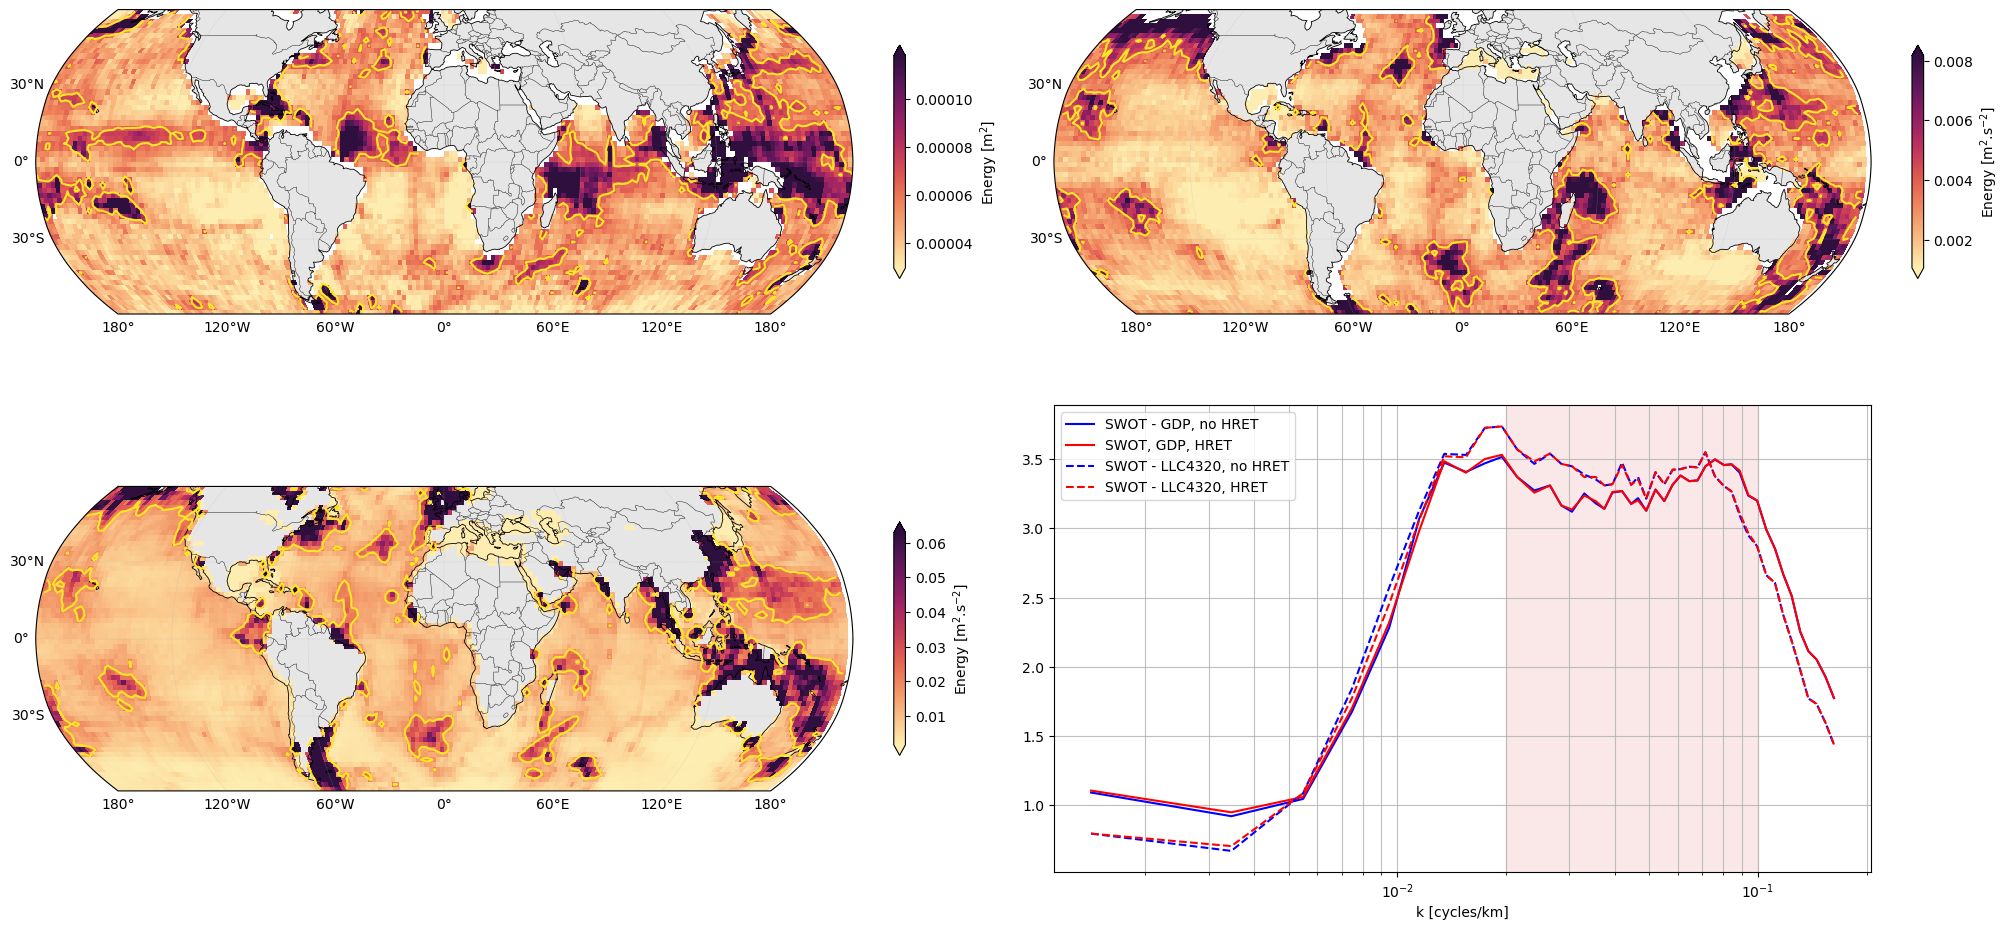

In [230]:
kmin,kmax = 1/50,1/10
top_q = 80
energy = ds_boxes_latlon.mean_psd.sel(wavenumber=slice(kmin,kmax)).integrate('wavenumber')
fig = plt.figure(figsize=(20,10),constrained_layout=True)
ax = fig.add_subplot(221,projection=ccrs.Robinson())
v0 = np.nanpercentile(energy,top_q)
_fig,ax = plot_latlon(energy,fig=fig,ax=ax,title=f'SWOT: Integrated PSD [{1/kmax:.0f} ; {1/kmin:.0f}] km',
                      cbar_kwargs={'shrink':0.5,'label':r'Energy [m$^2$]'})
ax.set_extent([-180,180,-60,60])
energy.plot.contour(ax=ax,levels=[v0],transform=ccrs.PlateCarree())
ax = fig.add_subplot(222,projection=ccrs.Robinson())
_fig,ax = plot_latlon(ds_gdp.E_energy.T,fig=fig,ax=ax,title=f'GDP: Kinetic energy, semidiurnal band',
                      cbar_kwargs={'shrink':0.5,'label':r'Energy [m$^2$.s$^{-2}$]'})
ax.set_extent([-180,180,-60,60])
ds_gdp.E_energy.T.plot.contour(ax=ax,levels=[np.nanpercentile(ds_gdp.E_energy.T,top_q)],transform=ccrs.PlateCarree())
ax = fig.add_subplot(223,projection=ccrs.Robinson())
_fig,ax = plot_latlon(ds_llc.E_energy,fig=fig,ax=ax,title=f'LLC4320: Kinetic energy, semidiurnal band',
                      cbar_kwargs={'shrink':0.5,'label':r'Energy [m$^2$.s$^{-2}$]'})
ax.set_extent([-180,180,-60,60])
ds_llc.E_energy.plot.contour(ax=ax,levels=[np.nanpercentile(ds_llc.E_energy,top_q)],transform=ccrs.PlateCarree())
ax = fig.add_subplot(224)
key = 'lift'
if key=='expected':
    ax.plot(curve_nohret.kc,100*curve_nohret[key],c='k',label='GDP, expected')
    ax.plot(curve_nohret_llc.kc,100*curve_nohret_llc[key],c='k',ls='--',label='LLC, expected')

    ax.plot(curve_nohret.kc,100*curve_nohret[key]*curve_nohret.lift,c='b',label='SWOT - GDP, no HRET')
    ax.plot(curve_nohret.kc,100*curve_hret[key]*curve_hret.lift,c='r',label='SWOT - GDP, HRET')
    ax.plot(curve_nohret_llc.kc,100*curve_nohret_llc[key]*curve_nohret_llc.lift,c='b',ls='--',label='SWOT - LLC4320, no HRET')
    ax.plot(curve_nohret_llc.kc,100*curve_hret_llc[key]*curve_hret_llc.lift,c='r',ls='--',label='SWOT - LLC4320, HRET')
if key=='r':
    ax.plot(curve_nohret.kc,curve_nohret[key],c='b',label='SWOT - GDP, no HRET')
    ax.plot(curve_nohret.kc,curve_hret[key],c='r',label='SWOT, GDP, HRET')
    ax.plot(curve_nohret_llc.kc,curve_nohret_llc[key],c='b',ls='--',label='SWOT - LLC4320, no HRET')
    ax.plot(curve_nohret_llc.kc,curve_hret_llc[key],c='r',ls='--',label='SWOT - LLC4320, HRET')
if key=='lift':
    ax.plot(curve_nohret.kc,curve_nohret[key],c='b',label='SWOT - GDP, no HRET')
    ax.plot(curve_nohret.kc,curve_hret[key],c='r',label='SWOT, GDP, HRET')
    ax.plot(curve_nohret_llc.kc,curve_nohret_llc[key],c='b',ls='--',label='SWOT - LLC4320, no HRET')
    ax.plot(curve_nohret_llc.kc,curve_hret_llc[key],c='r',ls='--',label='SWOT - LLC4320, HRET')
ax.axvspan(1/50, 1/10, color='C3', alpha=.1); ax.set_xscale('log'); ax.set_xlabel('k [cycles/km]')
ax.grid(which='both',alpha=0.8);ax.legend()

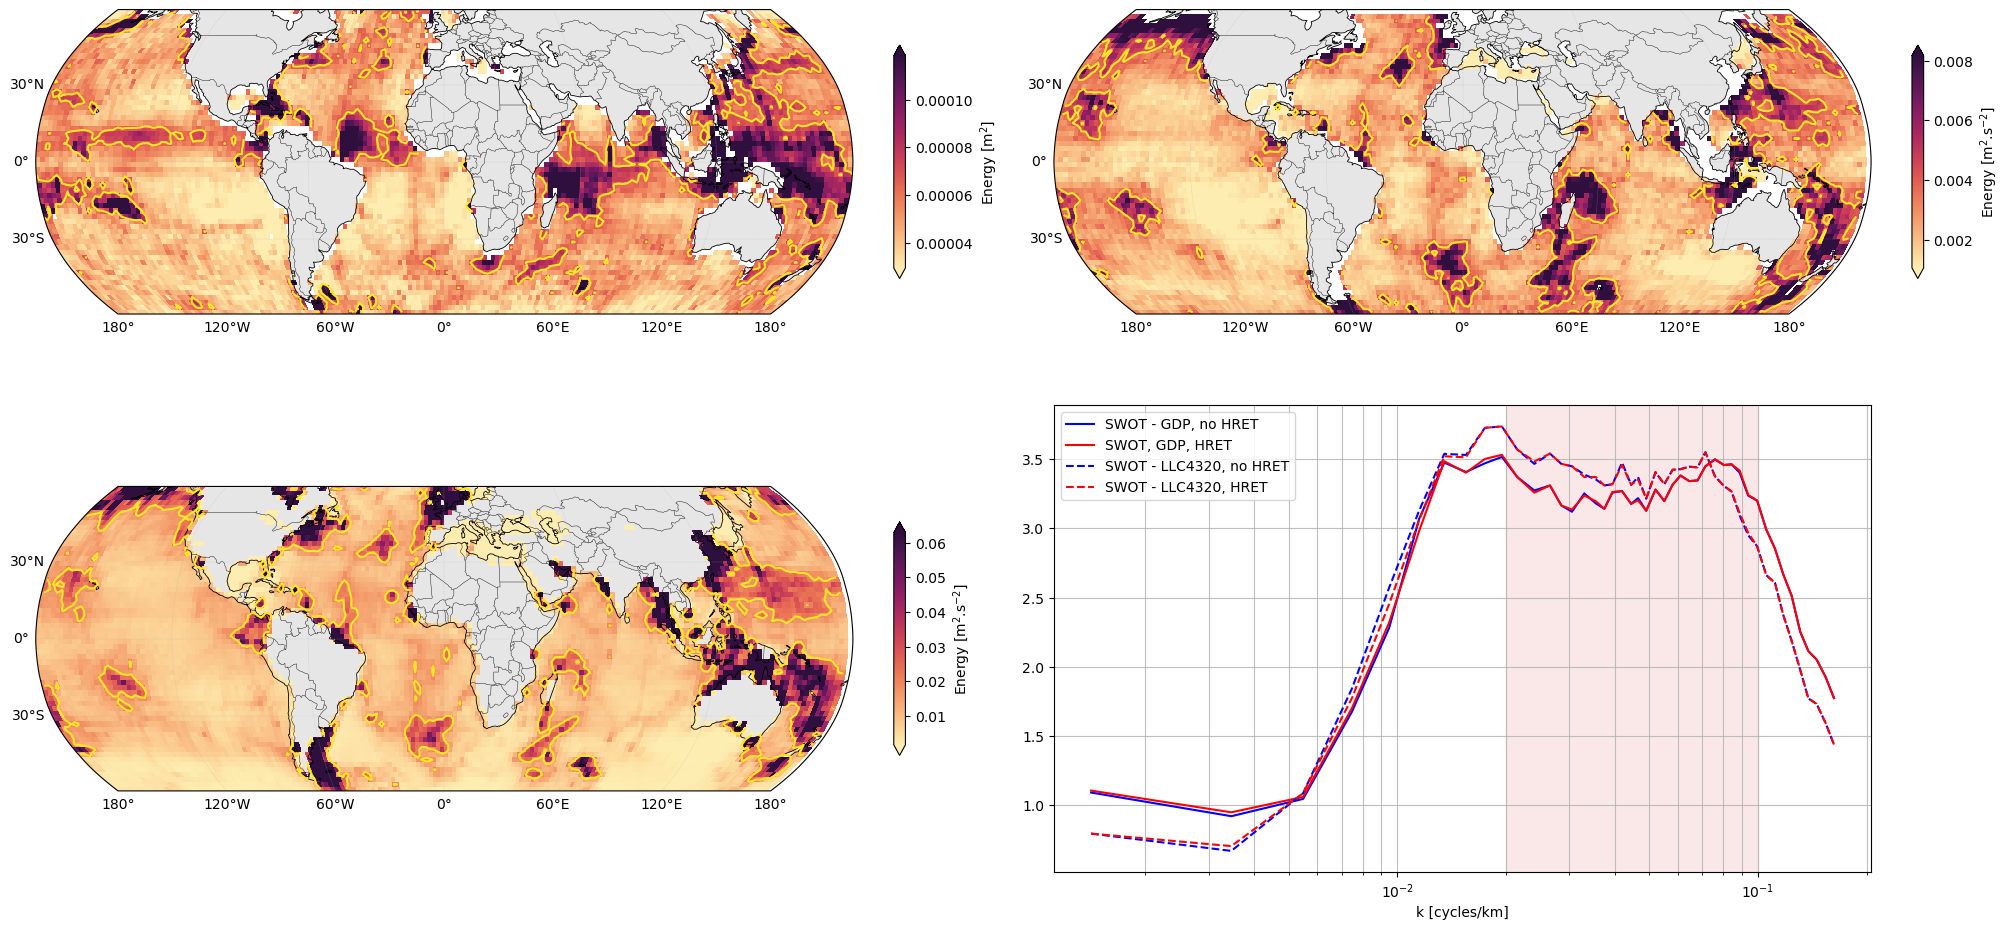

In [231]:
energy = ds_boxes_hret_latlon.mean_psd.sel(wavenumber=slice(kmin,kmax)).integrate('wavenumber')
fig = plt.figure(figsize=(20,10),constrained_layout=True)
ax = fig.add_subplot(221,projection=ccrs.Robinson())
v0 = np.nanpercentile(energy,top_q)
_fig,ax = plot_latlon(energy,fig=fig,ax=ax,title=f'SWOT: Integrated PSD [{1/kmax:.0f} ; {1/kmin:.0f}] km',
                      cbar_kwargs={'shrink':0.5,'label':r'Energy [m$^2$]'})
ax.set_extent([-180,180,-60,60])
energy.plot.contour(ax=ax,levels=[v0],transform=ccrs.PlateCarree())
ax = fig.add_subplot(222,projection=ccrs.Robinson())
_fig,ax = plot_latlon(ds_gdp.E_energy.T,fig=fig,ax=ax,title=f'GDP: Kinetic energy, semidiurnal band',
                      cbar_kwargs={'shrink':0.5,'label':r'Energy [m$^2$.s$^{-2}$]'})
ax.set_extent([-180,180,-60,60])
ds_gdp.E_energy.T.plot.contour(ax=ax,levels=[np.nanpercentile(ds_gdp.E_energy.T,top_q)],transform=ccrs.PlateCarree())
ax = fig.add_subplot(223,projection=ccrs.Robinson())
_fig,ax = plot_latlon(ds_llc.E_energy,fig=fig,ax=ax,title=f'LLC4320: Kinetic energy, semidiurnal band',
                      cbar_kwargs={'shrink':0.5,'label':r'Energy [m$^2$.s$^{-2}$]'})
ax.set_extent([-180,180,-60,60])
ds_llc.E_energy.plot.contour(ax=ax,levels=[np.nanpercentile(ds_llc.E_energy,top_q)],transform=ccrs.PlateCarree())
ax = fig.add_subplot(224)
key = 'lift'
if key=='expected':
    ax.plot(curve_nohret.kc,100*curve_nohret[key],c='k',label='GDP, expected')
    ax.plot(curve_nohret_llc.kc,100*curve_nohret_llc[key],c='k',ls='--',label='LLC, expected')

    ax.plot(curve_nohret.kc,100*curve_nohret[key]*curve_nohret.lift,c='b',label='SWOT - GDP, no HRET')
    ax.plot(curve_nohret.kc,100*curve_hret[key]*curve_hret.lift,c='r',label='SWOT - GDP, HRET')
    ax.plot(curve_nohret_llc.kc,100*curve_nohret_llc[key]*curve_nohret_llc.lift,c='b',ls='--',label='SWOT - LLC4320, no HRET')
    ax.plot(curve_nohret_llc.kc,100*curve_hret_llc[key]*curve_hret_llc.lift,c='r',ls='--',label='SWOT - LLC4320, HRET')
if key=='r':
    ax.plot(curve_nohret.kc,curve_nohret[key],c='b',label='SWOT - GDP, no HRET')
    ax.plot(curve_nohret.kc,curve_hret[key],c='r',label='SWOT, GDP, HRET')
    ax.plot(curve_nohret_llc.kc,curve_nohret_llc[key],c='b',ls='--',label='SWOT - LLC4320, no HRET')
    ax.plot(curve_nohret_llc.kc,curve_hret_llc[key],c='r',ls='--',label='SWOT - LLC4320, HRET')
if key=='lift':
    ax.plot(curve_nohret.kc,curve_nohret[key],c='b',label='SWOT - GDP, no HRET')
    ax.plot(curve_nohret.kc,curve_hret[key],c='r',label='SWOT, GDP, HRET')
    ax.plot(curve_nohret_llc.kc,curve_nohret_llc[key],c='b',ls='--',label='SWOT - LLC4320, no HRET')
    ax.plot(curve_nohret_llc.kc,curve_hret_llc[key],c='r',ls='--',label='SWOT - LLC4320, HRET')
ax.axvspan(1/50, 1/10, color='C3', alpha=.1); ax.set_xscale('log'); ax.set_xlabel('k [cycles/km]')
ax.grid(which='both',alpha=0.8);ax.legend()

In [260]:
ds_expert_swh5 = xr.open_dataset(DATA_DIR +'swot_segments2D_1000km_demean_swh5.nc')
ds250_expert_swh5 = xr.open_dataset(DATA_DIR +'swot_segments2D_250km_demean_swh5.nc')

ds_boxes_swh5 = build_latlon_dataset(ds_expert_swh5,box_deg=BOX_DEG,min_sampling_fraction=0.15)
ds250_boxes_swh5 = build_latlon_dataset(ds250_expert_swh5,box_deg=BOX_DEG,min_sampling_fraction=0.15)

ds_boxes_box_swh5 = build_box_dataset(ds_expert_swh5,box_deg=BOX_DEG,min_sampling_fraction=0.15)
ds250_boxes_box_swh5 = build_box_dataset(ds250_expert_swh5,box_deg=BOX_DEG,min_sampling_fraction=0.15)

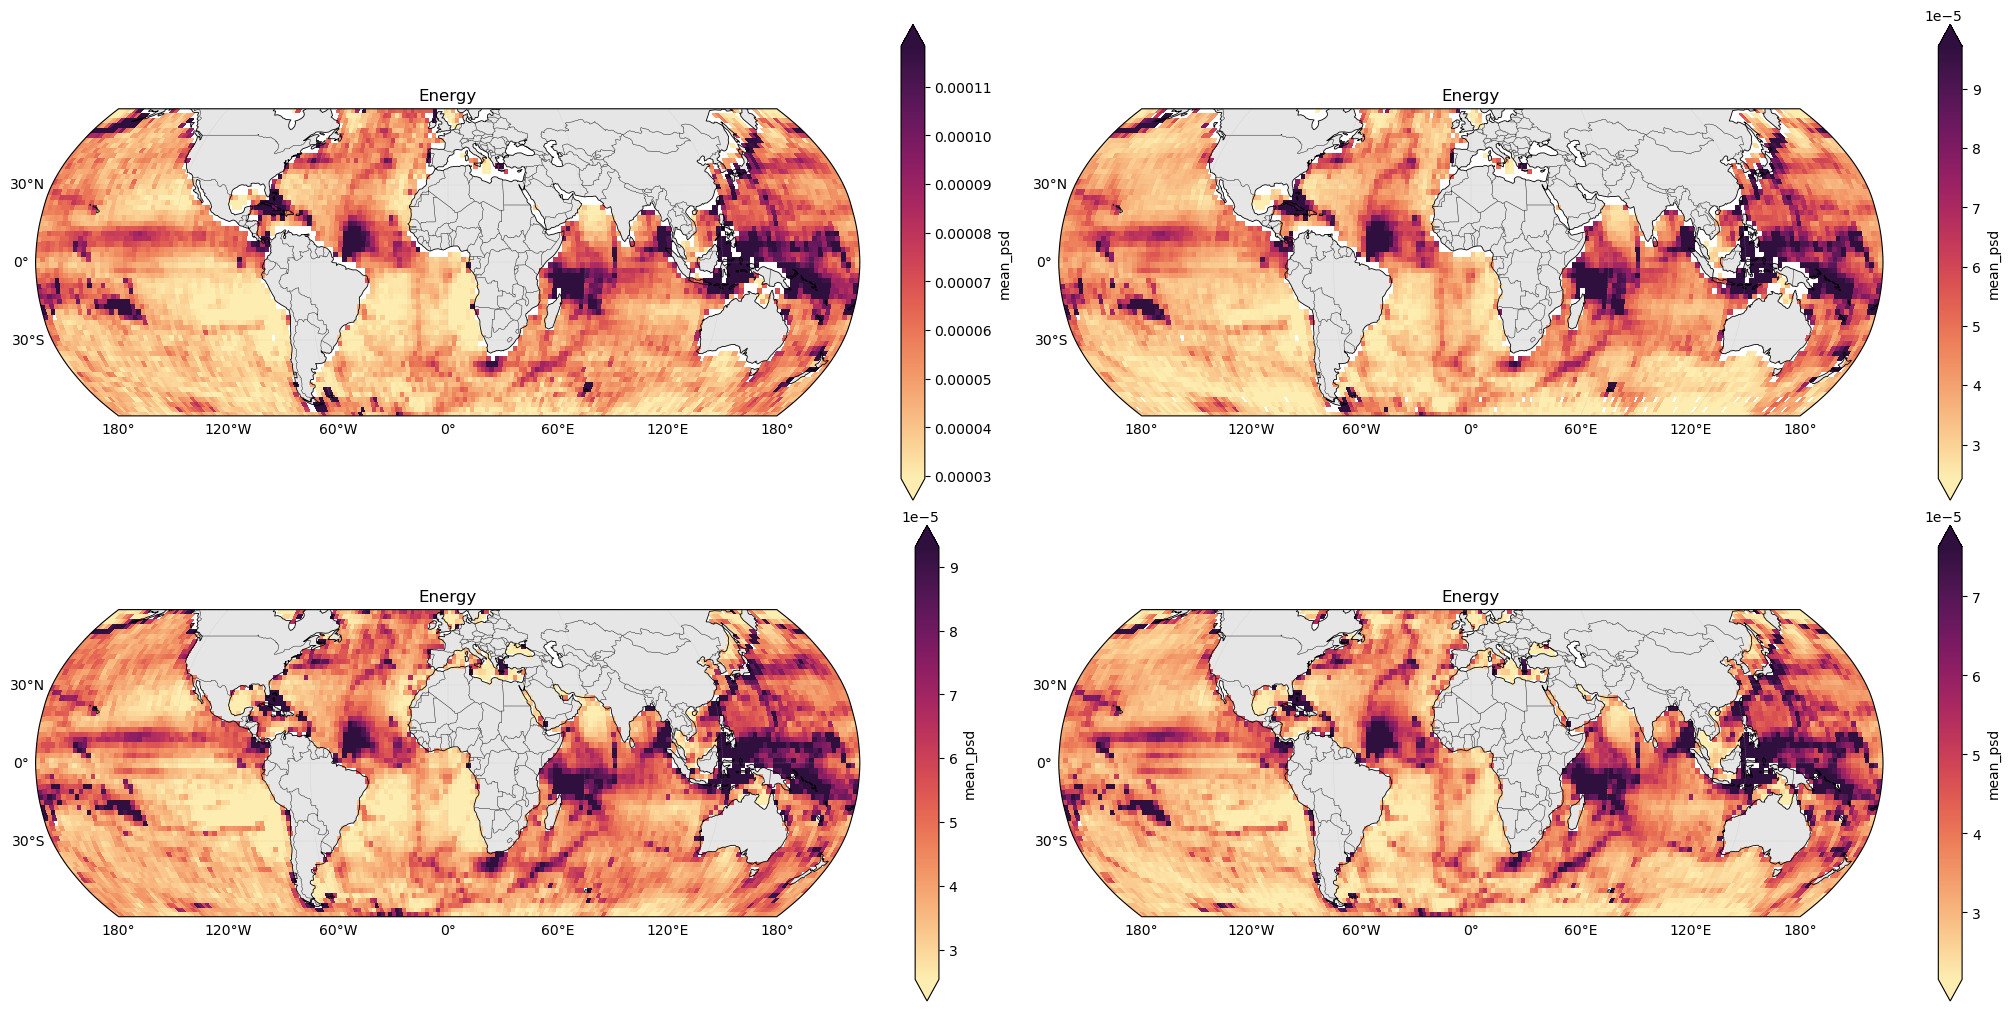

In [242]:
kmin, kmax = 1/50, 1/10
fig = plt.figure(figsize=(20,10),constrained_layout=True)
ax = fig.add_subplot(221,projection=ccrs.Robinson())
energy = ds_boxes_latlon.mean_psd.sel(wavenumber=slice(kmin,kmax)).integrate('wavenumber')
_fig,ax = plot_latlon(energy,fig=fig,ax=ax)
ax.set_extent([-180,180,-60,60])
ax = fig.add_subplot(222,projection=ccrs.Robinson())
energy = ds_boxes_swh5.mean_psd.sel(wavenumber=slice(kmin,kmax)).integrate('wavenumber')
_fig,ax = plot_latlon(energy,fig=fig,ax=ax)
ax.set_extent([-180,180,-60,60])

ax = fig.add_subplot(223,projection=ccrs.Robinson())
energy = ds250_boxes_latlon.mean_psd.sel(wavenumber=slice(kmin,kmax)).integrate('wavenumber')
_fig,ax = plot_latlon(energy,fig=fig,ax=ax)
ax.set_extent([-180,180,-60,60])
ax = fig.add_subplot(224,projection=ccrs.Robinson())
energy = ds250_boxes_swh5.mean_psd.sel(wavenumber=slice(kmin,kmax)).integrate('wavenumber')
_fig,ax = plot_latlon(energy,fig=fig,ax=ax)
ax.set_extent([-180,180,-60,60])

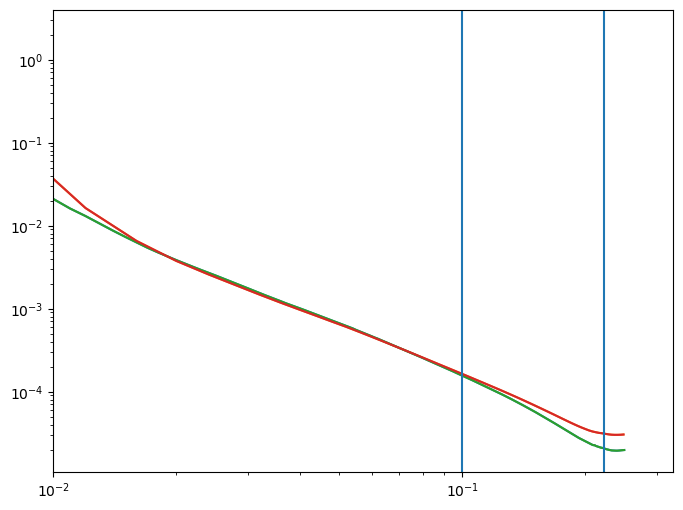

In [266]:
fig,ax = plt.subplots(figsize=(8,6))
ax.loglog(ds_expert.wavenumber, ds_expert.psd.mean('segment'))
ax.loglog(ds250_expert.wavenumber, ds250_expert.psd.mean('segment'))
ax.loglog(ds_expert_swh5.wavenumber, ds_expert.psd.mean('segment'))
ax.loglog(ds250_expert_swh5.wavenumber, ds250_expert.psd.mean('segment'))
ax.set_xlim(1/100,None);ax.axvline(1/10);ax.axvline(1/4.5)

In [307]:
ds_sep = wrap_separation_scale_adaptive(ds_boxes,
                                        low_k_band=(1/50, 1/10),
                                        high_k_band=(1/10, 1/5),
                                        smooth_window=15,
                                        verbose=False,
                                       )
ds250_sep = wrap_separation_scale_adaptive(ds250_boxes,
                                        low_k_band=(1/50, 1/10),
                                        high_k_band=(1/10, 1/5),
                                        smooth_window=15,
                                        verbose=False,
                                       )
ds_sep_swh5 = wrap_separation_scale_adaptive(ds_boxes_box_swh5,
                                        low_k_band=(1/50, 1/10),
                                        high_k_band=(1/10, 1/5),
                                        smooth_window=15,
                                        verbose=False,
                                       )
ds250_sep_swh5 = wrap_separation_scale_adaptive(ds250_boxes_box_swh5,
                                        low_k_band=(1/50, 1/10),
                                        high_k_band=(1/10, 1/5),
                                        smooth_window=15,
                                        verbose=False,
                                       )


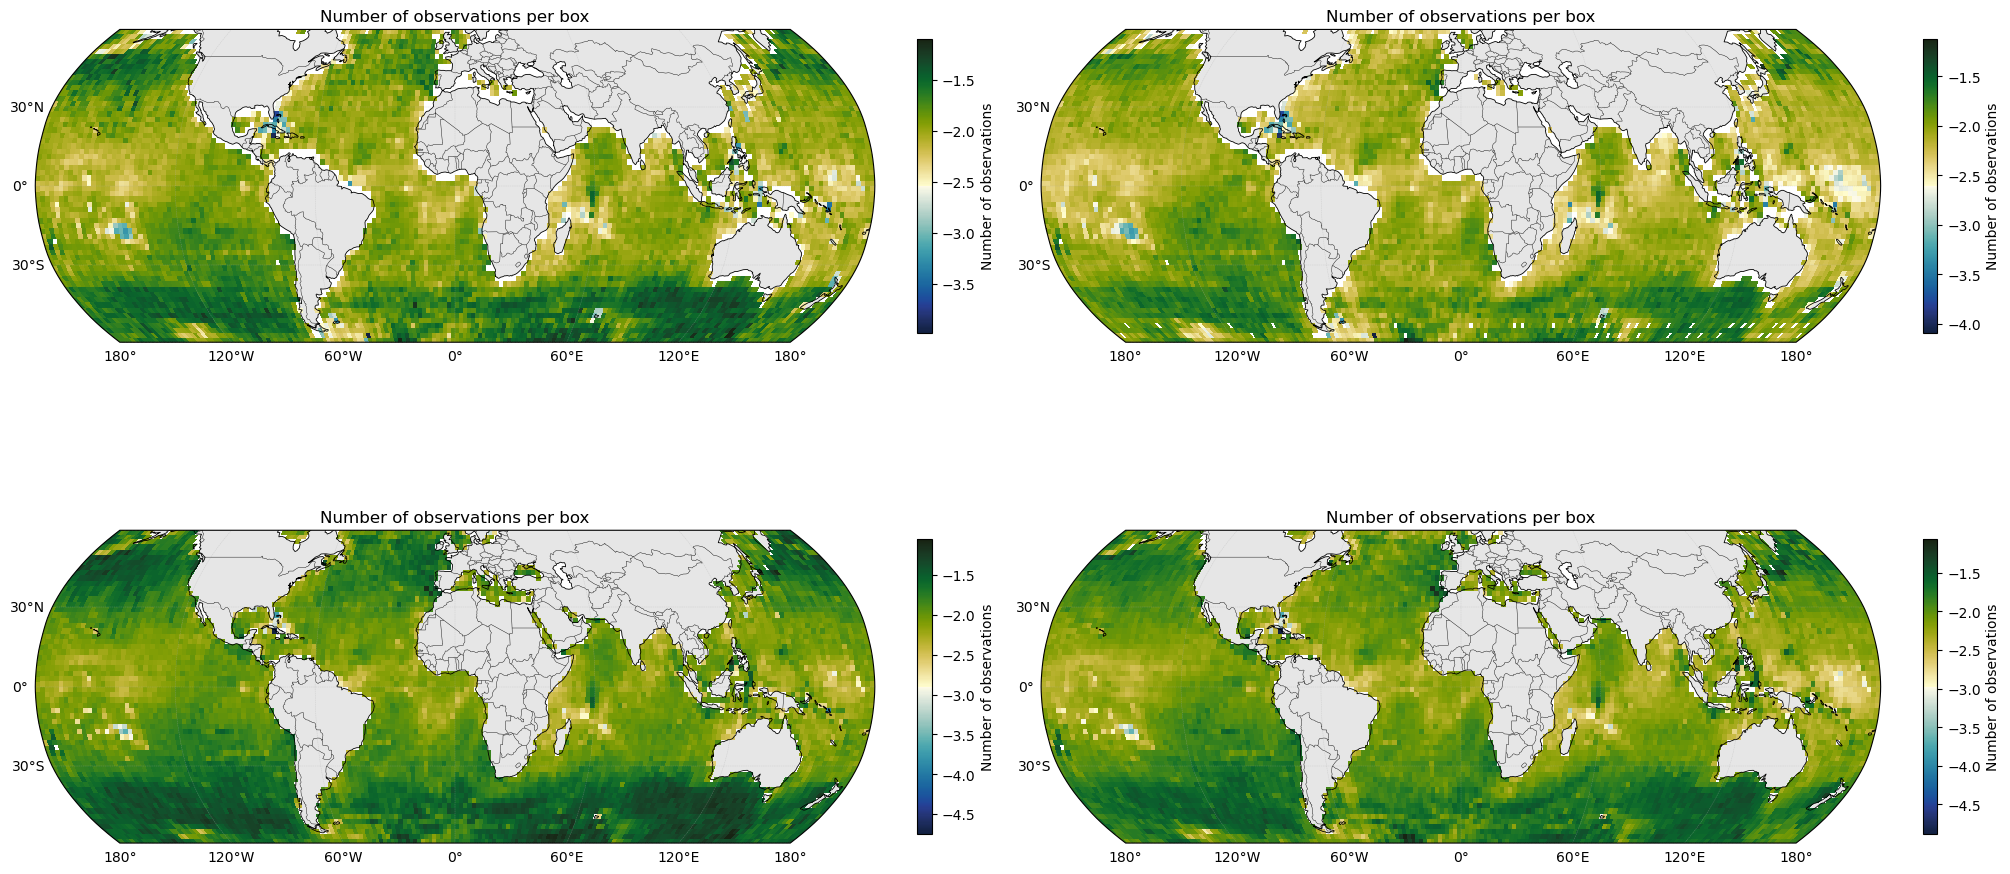

In [308]:
fig = plt.figure(figsize=(20,10),constrained_layout=True)
ax = fig.add_subplot(221,projection=ccrs.Robinson())
_fig,ax = plot_box(ds_sep.slope_low_k,ds_sep.lon_mean,ds_sep.lat_mean,cmap=cmocean.cm.delta,fig=fig,ax=ax)
ax.set_extent([-180,180,-60,60])
ax = fig.add_subplot(222,projection=ccrs.Robinson())
_fig,ax = plot_box(ds_sep_swh5.slope_low_k,ds_sep_swh5.lon_mean,ds_sep_swh5.lat_mean,cmap=cmocean.cm.delta,fig=fig,ax=ax)
ax.set_extent([-180,180,-60,60])
ax = fig.add_subplot(223,projection=ccrs.Robinson())
_fig,ax = plot_box(ds250_sep.slope_low_k,ds250_sep.lon_mean,ds250_sep.lat_mean,cmap=cmocean.cm.delta,fig=fig,ax=ax)
ax.set_extent([-180,180,-60,60])
ax = fig.add_subplot(224,projection=ccrs.Robinson())
_fig,ax = plot_box(ds250_sep_swh5.slope_low_k,ds250_sep_swh5.lon_mean,ds250_sep_swh5.lat_mean,cmap=cmocean.cm.delta,fig=fig,ax=ax)
ax.set_extent([-180,180,-60,60])

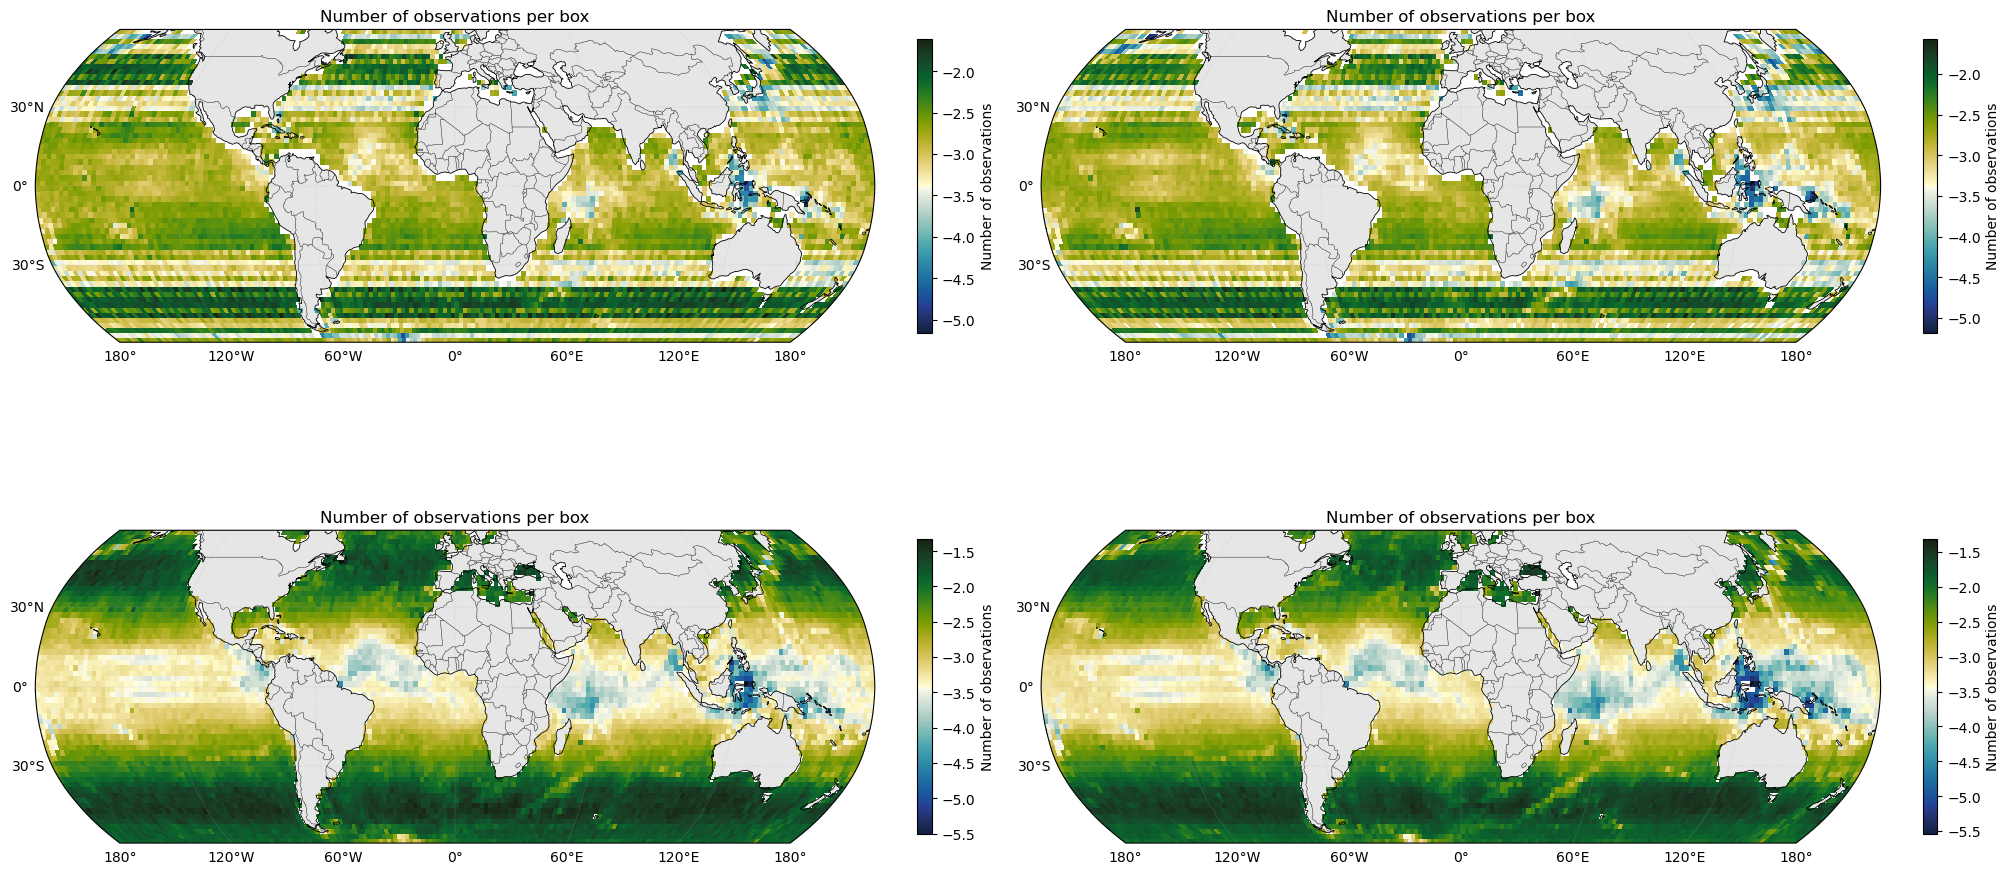

In [309]:
fig = plt.figure(figsize=(20,10),constrained_layout=True)
ax = fig.add_subplot(221,projection=ccrs.Robinson())
_fig,ax = plot_box(ds_sep.slope_high_k,ds_sep.lon_mean,ds_sep.lat_mean,cmap=cmocean.cm.delta,fig=fig,ax=ax)
ax.set_extent([-180,180,-60,60])
ax = fig.add_subplot(222,projection=ccrs.Robinson())
_fig,ax = plot_box(ds_sep_swh5.slope_high_k,ds_sep_swh5.lon_mean,ds_sep_swh5.lat_mean,cmap=cmocean.cm.delta,fig=fig,ax=ax)
ax.set_extent([-180,180,-60,60])
ax = fig.add_subplot(223,projection=ccrs.Robinson())
_fig,ax = plot_box(ds250_sep.slope_high_k,ds250_sep.lon_mean,ds250_sep.lat_mean,cmap=cmocean.cm.delta,fig=fig,ax=ax)
ax.set_extent([-180,180,-60,60])
ax = fig.add_subplot(224,projection=ccrs.Robinson())
_fig,ax = plot_box(ds250_sep_swh5.slope_high_k,ds250_sep_swh5.lon_mean,ds250_sep_swh5.lat_mean,cmap=cmocean.cm.delta,fig=fig,ax=ax)
ax.set_extent([-180,180,-60,60])

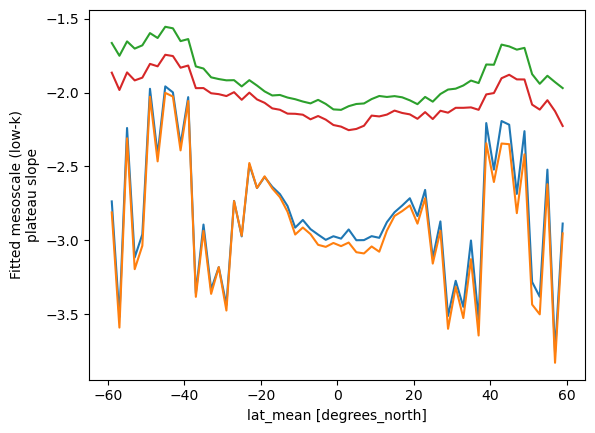

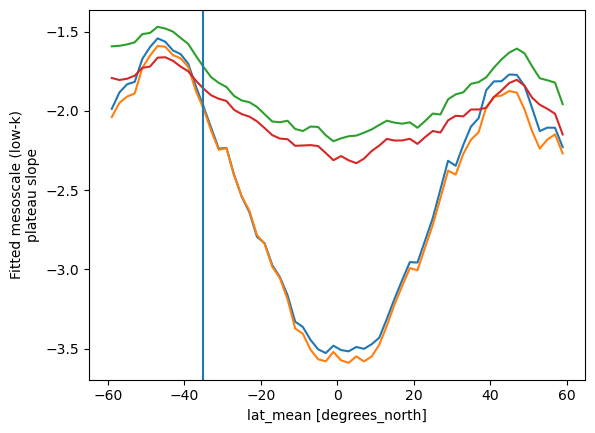

In [310]:
ds_sep.slope_high_k.groupby('lat_mean').mean().plot()
ds_sep_swh5.slope_high_k.groupby('lat_mean').mean().plot()
ds_sep.slope_low_k.groupby('lat_mean').mean().plot()
ds_sep_swh5.slope_low_k.groupby('lat_mean').mean().plot()

plt.figure()
ds250_sep.slope_high_k.groupby('lat_mean').mean().plot()
ds250_sep_swh5.slope_high_k.groupby('lat_mean').mean().plot()
ds250_sep.slope_low_k.groupby('lat_mean').mean().plot()
ds250_sep_swh5.slope_low_k.groupby('lat_mean').mean().plot()
plt.axvline(-35)

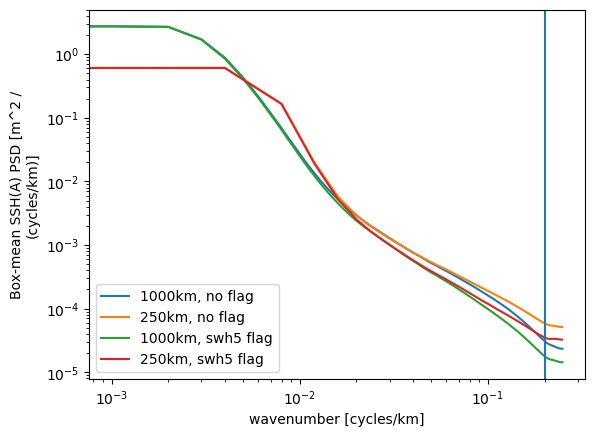

In [311]:
ds_sep.where(ds_sep.lat_mean<=-35,drop=True).mean('box').mean_psd.plot(xscale='log',yscale='log',label=f'1000km, no flag')
ds250_sep.where(ds250_sep.lat_mean<=-35,drop=True).mean('box').mean_psd.plot(xscale='log',yscale='log',label='250km, no flag')

ds_sep_swh5.where(ds_sep.lat_mean<=-35,drop=True).mean('box').mean_psd.plot(xscale='log',yscale='log',label='1000km, swh5 flag')
ds250_sep_swh5.where(ds250_sep.lat_mean<=-35,drop=True).mean('box').mean_psd.plot(xscale='log',yscale='log',label='250km, swh5 flag')
plt.legend();plt.axvline(1/5)

In [312]:
print('1000km: ')
print(f'high k slope, no flag: {ds_sep.where(ds_sep.lat_mean<=-35,drop=True).mean('box').slope_high_k.values}')
print(f'low k slope, no flag: {ds_sep.where(ds_sep.lat_mean<=-35,drop=True).mean('box').slope_low_k.values}')

print(f'high k slope, swh5 flag: {ds_sep_swh5.where(ds_sep_swh5.lat_mean<=-35,drop=True).mean('box').slope_high_k.values}')
print(f'low k slope, swh5 flag: {ds_sep_swh5.where(ds_sep_swh5.lat_mean<=-35,drop=True).mean('box').slope_low_k.values}')

print('250km: ')
print(f'high k slope, no flag: {ds250_sep.where(ds250_sep.lat_mean<=-35,drop=True).mean('box').slope_high_k.values}')
print(f'low k slope, no flag: {ds250_sep.where(ds250_sep.lat_mean<=-35,drop=True).mean('box').slope_low_k.values}')


print(f'high k slope, swh5 flag: {ds250_sep_swh5.where(ds250_sep_swh5.lat_mean<=-35,drop=True).mean('box').slope_high_k.values}')
print(f'low k slope, swh5 flag: {ds250_sep_swh5.where(ds250_sep_swh5.lat_mean<=-35,drop=True).mean('box').slope_low_k.values}')

1000km: 
high k slope, no flag: -2.5781905666571294
low k slope, no flag: -1.6715282328827885
high k slope, swh5 flag: -2.61713762691644
low k slope, swh5 flag: -1.862618354794229
250km: 
high k slope, no flag: -1.7435158578947314
low k slope, no flag: -1.5596461700998354
high k slope, swh5 flag: -1.7884454606757247
low k slope, swh5 flag: -1.750668585761002


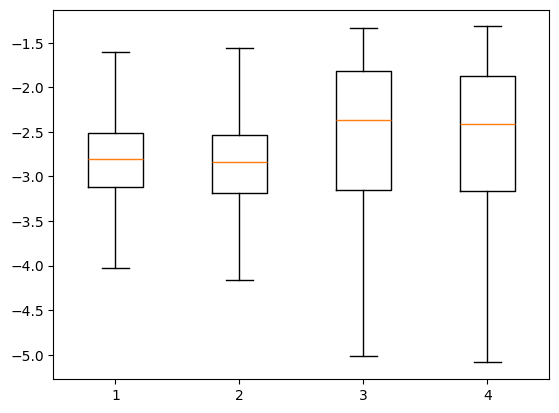

In [317]:
fig,ax = plt.subplots()
_ = ax.boxplot([ds_sep.slope_high_k,ds_sep_swh5.slope_high_k,ds250_sep.slope_high_k,ds250_sep_swh5.slope_high_k],showfliers=False)

In [335]:
boxplots, labels = [], []
boxplots_swh5,boxplots250_swh5,boxplots250 = [],[],[]
plot_var = 'slope_low_k'
for latmin, latmax in zip([-60,-35,35], [-35,35,60]):
    boxplots.append(ds_sep.where((ds_sep.lat_mean>latmin)&(ds_sep.lat_mean<=latmax),drop=True)[plot_var])
    boxplots_swh5.append(ds_sep_swh5.where((ds_sep_swh5.lat_mean>latmin)&(ds_sep_swh5.lat_mean<=latmax),drop=True)[plot_var])
    boxplots250_swh5.append(ds250_sep_swh5.where((ds250_sep_swh5.lat_mean>latmin)&(ds250_sep_swh5.lat_mean<=latmax),drop=True)[plot_var])
    boxplots250.append(ds250_sep.where((ds250_sep.lat_mean>latmin)&(ds250_sep.lat_mean<=latmax),drop=True)[plot_var])
    labels.append(f'[{latmin:02d}°N ; {latmax:02d}°N]')

In [337]:
_boxplots, labels = [], []
_boxplots_swh5,_boxplots250_swh5,_boxplots250 = [],[],[]
plot_var = 'slope_high_k'
for latmin, latmax in zip([-60,-35,35], [-35,35,60]):
    _boxplots.append(ds_sep.where((ds_sep.lat_mean>latmin)&(ds_sep.lat_mean<=latmax),drop=True)[plot_var])
    _boxplots_swh5.append(ds_sep_swh5.where((ds_sep_swh5.lat_mean>latmin)&(ds_sep_swh5.lat_mean<=latmax),drop=True)[plot_var])
    _boxplots250_swh5.append(ds250_sep_swh5.where((ds250_sep_swh5.lat_mean>latmin)&(ds250_sep_swh5.lat_mean<=latmax),drop=True)[plot_var])
    _boxplots250.append(ds250_sep.where((ds250_sep.lat_mean>latmin)&(ds250_sep.lat_mean<=latmax),drop=True)[plot_var])
    labels.append(f'[{latmin:02d}°N ; {latmax:02d}°N]')

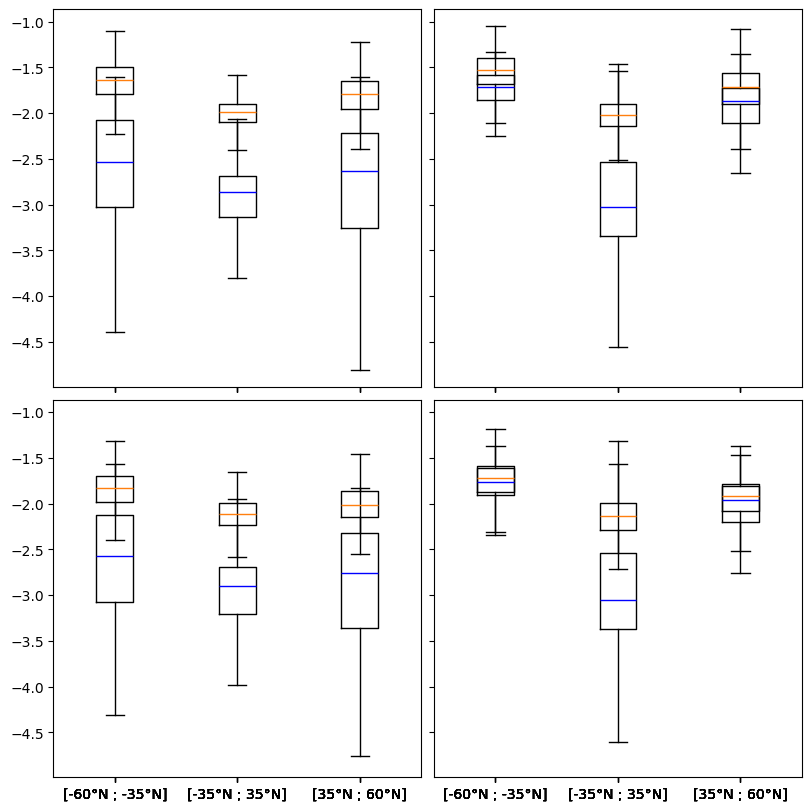

In [345]:
fig,ax = plt.subplots(2,2,figsize=(8,8),sharey=True,sharex=True,constrained_layout=True)
_ = ax[0,0].boxplot(boxplots,tick_labels=labels,showfliers=False)
_ = ax[0,0].boxplot(_boxplots,tick_labels=labels,showfliers=False)
for m in _['medians']:
    m.set_color('b')
_ = ax[1,0].boxplot(boxplots_swh5,tick_labels=labels,showfliers=False)
_ = ax[1,0].boxplot(_boxplots_swh5,tick_labels=labels,showfliers=False)
for m in _['medians']:
    m.set_color('b')
_ = ax[0,1].boxplot(boxplots250,tick_labels=labels,showfliers=False)
_ = ax[0,1].boxplot(_boxplots250,tick_labels=labels,showfliers=False)
for m in _['medians']:
    m.set_color('b')
_ = ax[1,1].boxplot(boxplots250_swh5,tick_labels=labels,showfliers=False)
_ = ax[1,1].boxplot(_boxplots250_swh5,tick_labels=labels,showfliers=False)
for m in _['medians']:
    m.set_color('b')

In [346]:
# Seasonality